In [ ]:
# Locate this checkout when launched from the repository or notebook folder.
from pathlib import Path
import sys
_REPOSITORY_ROOT = next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "aerosandbox/__init__.py").is_file()
    and (p / "studies/TSher_Improvements").is_dir()
)
_STUDY_DIRECTORY = _REPOSITORY_ROOT / "studies/TSher_Improvements/ctol/headless_chicken"
for _path in [_REPOSITORY_ROOT, _STUDY_DIRECTORY]:
    if str(_path) not in sys.path:
        sys.path.insert(0, str(_path))


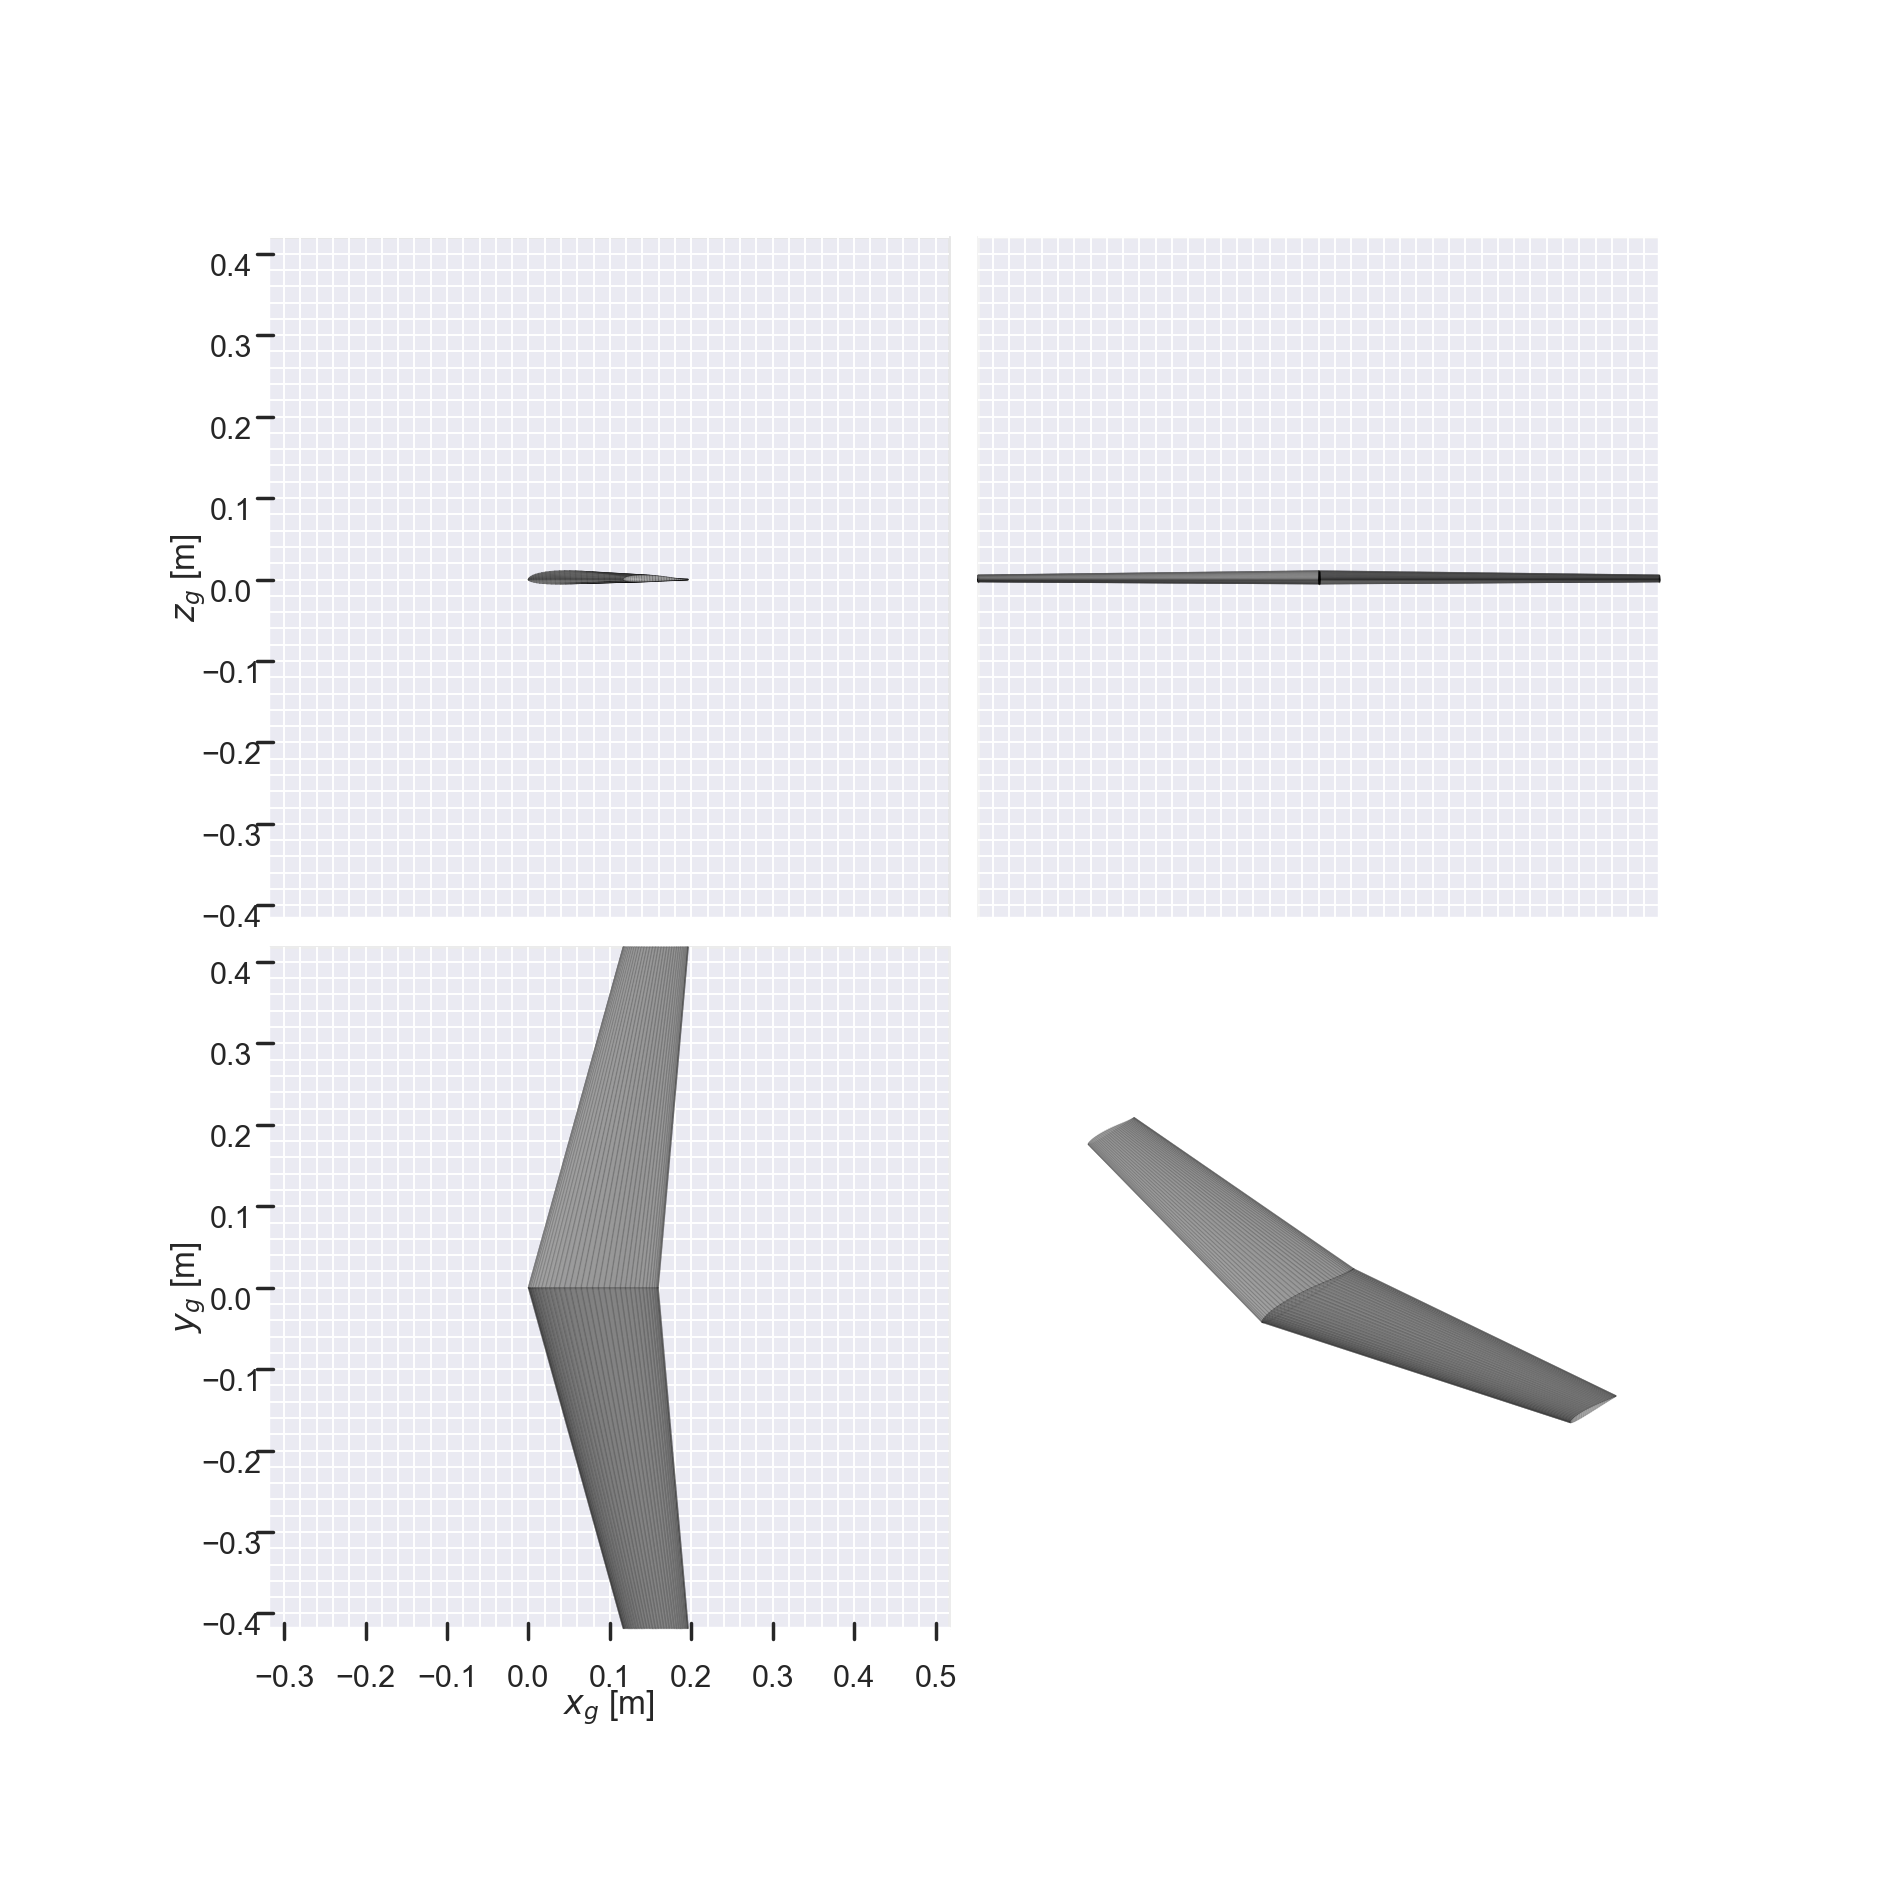

Aircraft Geometry:
S: 0.1 m^2
AR: 7
b: 0.8366600265340756 m
taper: 0.5
twist: 0 deg
sweep: 13 deg
c_root: 0.15936381457791915 m
c_tip: 0.07968190728895957 m
x_cg: 0.07968190728895957 m

Empirical Neutral Point:
Empirical x_np: 0.08276499518069927 m
Empirical SM: 0.02487371525977326

LLM Results:
LLM CL: 0.6212001481068203
LLM CD: 0.03479451613362292
LLM CM: -0.03646675793635419
LLM x_np: 0.08103590207640225 m
LLM SM: 0.010923749821177624

VLM Results:
VLM CL: 0.5989657519318138
VLM CD: 0.016217525886679227
VLM CM: -0.016833385266725485
VLM x_np: 0.08206741973230934 m
VLM SM: 0.019245820861450116


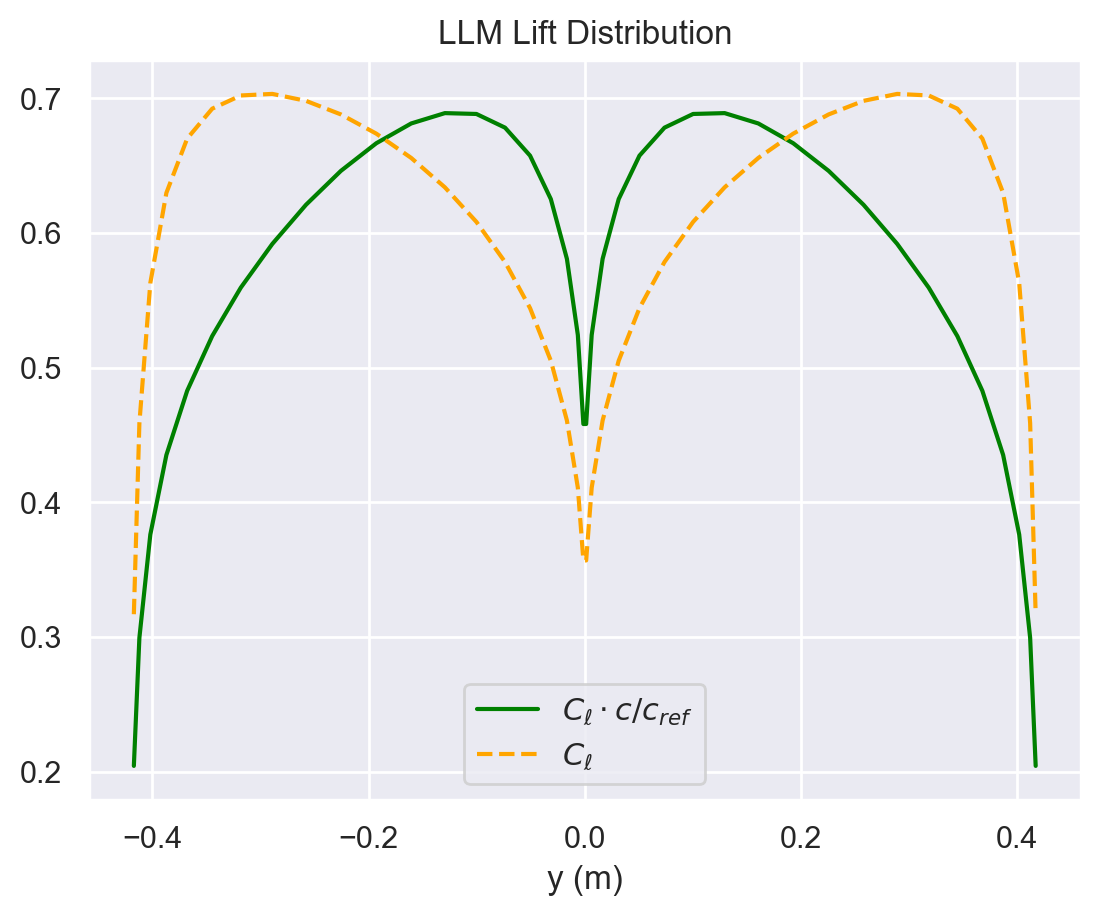

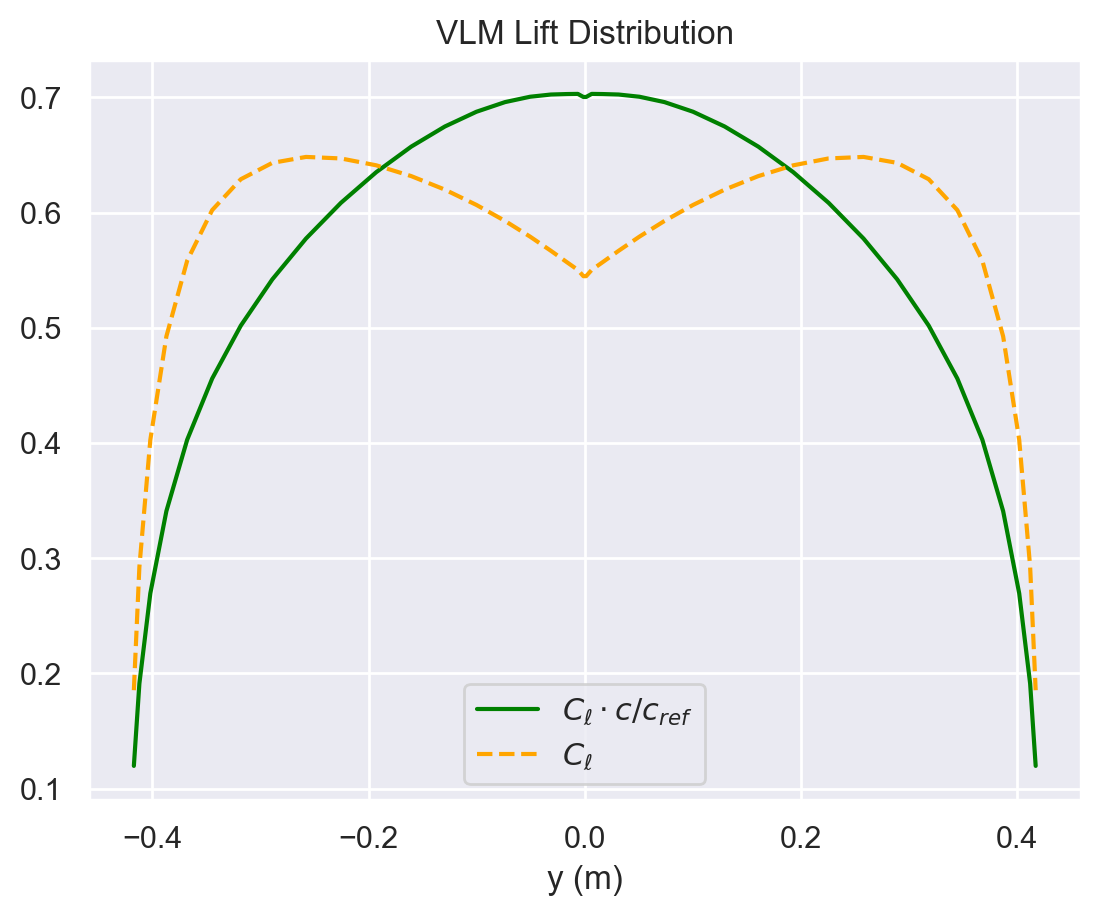


Reynolds Numbers
Root Re: 158287.03204698724
Tip Re: 79143.51602349362


In [74]:
import aerosandbox as asb
import aerosandbox.numpy as np
import matplotlib.pyplot as plt

# Geomteric Parameters
S = 0.1  # [m^2]
AR = 7  # []
b = np.sqrt(S * AR)  # [m]
taper_ratio = 0.5
twist = 0  # [deg]
sweep = 13  # [deg]
c_root = (2 * S) / (b * (1 + taper_ratio))  # [m]
c_tip = taper_ratio * c_root  # [m]
x_cg = c_root / 2  # [m]

# Weight and CG estimation TODO
# Core
# Skin
# Servos
# Wiring
# Ballast
# Mounts
# Elevons

# Operating Point
velocity = 15  # [m/s]
alpha = 7  # [m/s]

# Solver parameters
n_spanwise = 20
n_chordwise = 10

# Geometry Definition
airplane = asb.Airplane(
    name="HC-1",
    xyz_ref=[x_cg, 0, 0],
    wings=[
        asb.Wing(
            name="Wing",
            symmetric=True,
            xsecs=[
                asb.WingXSec(
                    xyz_le=[0, 0, 0],
                    chord=c_root,
                    twist=0,
                    airfoil=asb.Airfoil("mh45"),
                ),
                asb.WingXSec(
                    xyz_le=[0.25*(c_root - c_tip) + (b/2)*np.tan(sweep*np.pi/180), b/2, 0],
                    chord=c_tip,
                    twist=twist,
                    airfoil=asb.Airfoil("mh45"),
                ),
            ],
        )
    ],
)

# Draw plane
airplane.draw_three_view()

# Print geometric parameters
print("Aircraft Geometry:")
print(f"S: {S} m^2")
print(f"AR: {AR}")
print(f"b: {b} m")
print(f"taper: {taper_ratio}")
print(f"twist: {twist} deg")
print(f"sweep: {sweep} deg")
print(f"c_root: {c_root} m")
print(f"c_tip: {c_tip} m")
print(f"x_cg: {x_cg} m")

# Empirical neural point and static margin
x_np = airplane.aerodynamic_center()[0]
MAC = airplane.c_ref
SM = (x_np - x_cg) / MAC

print("\nEmpirical Neutral Point:")
print(f"Empirical x_np: {x_np} m")
print(f"Empirical SM: {SM}")

# Lifting line
op_point = asb.OperatingPoint(velocity=velocity, alpha=alpha)

llm = asb.LiftingLine(
    airplane=airplane,
    op_point=op_point,
    spanwise_resolution=n_spanwise,
    align_trailing_vortices_with_wind=False,
)
llm_results = llm.run_with_stability_derivatives(alpha=True)

print("\nLLM Results:")
print(f"LLM CL: {llm_results["CL"]}")
print(f"LLM CD: {llm_results["CD"]}")
print(f"LLM CM: {llm_results["Cm"]}")
print(f"LLM x_np: {llm_results["x_np"]} m")
print(f"LLM SM: {(llm_results["x_np"] - x_cg) / MAC}")

# Vortex Lattice
vlm = asb.VortexLatticeMethod(
    airplane=airplane,
    op_point=op_point,
    spanwise_resolution=n_spanwise,
    chordwise_resolution=n_chordwise,
    align_trailing_vortices_with_wind=False,
)
vlm_results = vlm.run_with_stability_derivatives(alpha=True)

print("\nVLM Results:")
print(f"VLM CL: {vlm_results["CL"]}")
print(f"VLM CD: {vlm_results["CD"]}")
print(f"VLM CM: {vlm_results["Cm"]}")
print(f"VLM x_np: {vlm_results["x_np"]} m")
print(f"VLM SM: {(vlm_results["x_np"] - x_cg) / MAC}")

# Lift Distributions
# LLM
y_llm = llm_results["y"][0]
clc_over_cref_llm = llm_results["clc_over_cref"][0]
cl_llm = llm_results["cl"][0]

plt.figure()
plt.plot(y_llm, clc_over_cref_llm, color="green", label=r"$C_{\ell} \cdot c/c_{ref}$")
plt.plot(y_llm, cl_llm, color="orange", linestyle="--", label=r"$C_{\ell}$")
plt.title("LLM Lift Distribution")
plt.xlabel("y (m)")
plt.legend()
plt.show()

# VLM
y_vlm = vlm_results["y"][0]
clc_over_cref_vlm = vlm_results["clc_over_cref"][0]
cl_vlm = vlm_results["cl"][0]

plt.figure()
plt.plot(y_vlm, clc_over_cref_vlm, color="green", label=r"$C_{\ell} \cdot c/c_{ref}$")
plt.plot(y_vlm, cl_vlm, color="orange", linestyle="--", label=r"$C_{\ell}$")
plt.title("VLM Lift Distribution")
plt.xlabel("y (m)")
plt.legend()
plt.show()

# Reynolds Numbers
print("\nReynolds Numbers")
print(f"Root Re: {(1.225 * velocity * c_root) / (1.85*10**-5)}")
print(f"Tip Re: {(1.225 * velocity * c_tip) / (1.85*10**-5)}")